In [1]:
import numpy as np
import cv2
import os
import string
import matplotlib.pyplot as plt
import tqdm
from os.path import join
from collections import Counter
import re
import io
import copy
from tensorflow.keras import layers
import editdistance

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers

from tensorflow.keras.layers import Dense, LSTM,GRU, Reshape, BatchNormalization, Input, Conv2D, MaxPool2D, Lambda, Bidirectional
from tensorflow.keras.models import Model
from tensorflow.keras.activations import relu, sigmoid, softmax
import tensorflow.keras.backend as K
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Baseline was launched on a machine with the following library versions:

In [ ]:
import keras
import tensorflow as tf
print('TensorFlow version:', tf.__version__)
print('Keras version:', keras.__version__)

TensorFlow version: 2.15.0
Keras version: 2.15.0


* CUDA 10.1
* cv2 4.3.0
* numpy 1.19.2
* re 2.2.1
* tqdm 4.46.0
* matplotlib 3.3.2

Let's specify the paths for images and text.

In [3]:
#This folder contains translation txt files
trans_dir = '/content/drive/MyDrive/train/words'
#trans_dir = 'train/words'
#This folder contains jpg image files
#image_dir = 'train/images'
image_dir = '/content/drive/MyDrive/train/images'
print(len(os.listdir(trans_dir)))
print(len(os.listdir(image_dir)))

1227
1227


In [4]:
import os
import shutil

# Define the paths to the folders
image_folder = '/content/drive/MyDrive/train/images'
text_folder = '/content/drive/MyDrive/train/words'

temp_folder = '/content/drive/MyDrive/train/extra'



# Create the "Temp" folder if it doesn't exist
if not os.path.exists(temp_folder):
    os.makedirs(temp_folder)

# Get a list of all text files in the "Text" folder
text_files = [file.replace(".txt", "") for file in os.listdir(text_folder) if file.endswith(".txt")]

# Iterate over image files in the "images" folder
for image_file in os.listdir(image_folder):
    # Check if the corresponding text file exists
    if image_file.replace(".jpg", "").replace(".jpeg", "").replace(".png", "") not in text_files:
        # Move the image file to the "Temp" folder
        shutil.move(os.path.join(image_folder, image_file), os.path.join(temp_folder, image_file))

print("Files moved to 'Temp' folder.")

Files moved to 'Temp' folder.


In [ ]:
import os
import shutil

# Define the paths to the folders
#image_folder = "All Image of Text Line"
#text_folder = "P Text Line"

temp1_folder = '/content/drive/MyDrive/train/extra'
image_folder = '/content/drive/MyDrive/train/images'
text_folder = '/content/drive/MyDrive/train/words'



# Create the "Temp1" folder if it doesn't exist
if not os.path.exists(temp1_folder):
    os.makedirs(temp1_folder)

# Get a list of all image files in the "images" folder
image_files = [file.replace(".jpg", "").replace(".jpeg", "").replace(".png", "") for file in os.listdir(image_folder)
               if file.endswith((".jpg", ".jpeg", ".png"))]

# Iterate over text files in the "Text" folder
for text_file in os.listdir(text_folder):
    # Check if the corresponding image file exists
    if text_file.replace(".txt", "") not in image_files:
        # Move the text file to the "Temp1" folder
        shutil.move(os.path.join(text_folder, text_file), os.path.join(temp1_folder, text_file))

print("Files moved to 'Temp1' folder.")

Files moved to 'Temp1' folder.


Let's look at a separate image.

In [5]:
example = os.listdir(image_dir)[0]

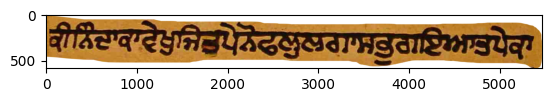

In [6]:
img = plt.imread(image_dir+'/'+example)
plt.imshow(img)
plt.show()

And its translation.

In [7]:
with io.open(trans_dir+'/'+example[:-3]+'txt', 'r',  encoding='utf8') as file:
    data = file.read()

print(data)

ਕੀਨਿੰਦਾਕਾਵੇਖੁਜਿਤਪੇਨੋਫਲੁਲਗਾਸਭੁਗਇਆਤਪੇਕਾ


The texts contain words containing English characters.

But since there are not very many English characters in general, you can remove lines with them from the train sample (and train only on the remaining lines). This is what we will do in the current baseline. This will shorten the alphabet (and, as a result, save us from unnecessary noise).

At the same time, you need to understand that English characters will most likely be present in the test sample. Therefore, there will be forced errors associated with our arbitrary filtering of the training sample.

However, you always choose the recognition method yourself.

In addition, we advise you to carefully study the train sample with your eyes.

In [8]:
english = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'm', 'n' ,'o', 'p', 'r', 's', 't', 'u', 'w']

In [9]:
def text_to_labels(text):
    return list(map(lambda x: letters.index(x), text))

The next function prepares labels, that is, translated text. As already mentioned, examples containing English letters are ignored.

In [10]:
def process_texts(image_dir,trans_dir):
    lens = []
    include_english = 0
    letters = ''

    lines = []
    names = []

    all_files = os.listdir(trans_dir)
    for filename in os.listdir(image_dir):
        if filename[:-3]+'txt' in all_files:
            name, ext = os.path.splitext(filename)
            txt_filepath = join(trans_dir, name + '.txt')
            with open(txt_filepath, 'r') as file:
                data = file.read()
                if len(data)==0:
                    continue
                if len(set(data).intersection(english))>0:
                    continue

                lines.append(data)
                names.append(filename)
                lens.append(len(data))
                letters += data
    print('Maximum line length:', max(Counter(lens).keys()))
    print('Number of lines with English letters',include_english)

    return names,lines,Counter(letters)

As a result, we get a list of images, a corresponding processed list of strings, and a dictionary of characters.

In [ ]:
names,lines,cnt = process_texts(image_dir,trans_dir)

In [ ]:
letters = set(cnt.keys())

letters = sorted(list(letters))
print('Symbol train:', ' '.join(letters))

Symbol train:   : । ॥ ਂ ਅ ਆ ਇ ਈ ਉ ਊ ਏ ਐ ਓ ਕ ਖ ਗ ਘ ਚ ਛ ਜ ਝ ਟ ਠ ਡ ਢ ਣ ਤ ਥ ਦ ਧ ਨ ਪ ਫ ਬ ਭ ਮ ਯ ਰ ਲ ਵ ਸ ਹ ਾ ਿ ੀ ੁ ੂ ੇ ੈ ੋ ੌ ੍ ੜ ੦ ੧ ੨ ੩ ੪ ੫ ੬ ੭ ੮ ੯ ੰ ੴ


The next function loads images, resizes them to the required size and normalizes them.

In [ ]:
def process_image(img):
    w, h,_ = img.shape

    new_w = 128
    new_h = int(h * (new_w / w))
    img = cv2.resize(img, (new_h, new_w))
    w, h,_ = img.shape

    img = img.astype('float32')

    if w < 128:
        add_zeros = np.full((128-w, h,3), 255)
        img = np.concatenate((img, add_zeros))
        w, h,_ = img.shape

    if h < 1024:
        add_zeros = np.full((w, 1024-h,3), 255)
        img = np.concatenate((img, add_zeros), axis=1)
        w, h,_ = img.shape

    if h > 1024 or w > 128:
        dim = (1024,128)
        img = cv2.resize(img, dim)

    img = cv2.subtract(255, img)

    img = img / 255

    return img

Let's prepare training and validation data.

In [ ]:
def generate_data(lines,names,image_dir):
    data_images = []
    data_labels = []
    data_input_length = []
    data_label_length = []
    data_original_text = []
    data_original_image = []

    max_label_len = 0
    for line, name in tqdm.tqdm_notebook(zip(lines,names)):
        img = cv2.imread(image_dir+'/'+name)
        original_image = copy.deepcopy(img)
        img = process_image(img)
        try:
            label = text_to_labels(line)
        except:
            print('bad_label')
            continue
        data_images.append(img)
        data_labels.append(label)
        data_input_length.append(255)
        data_label_length.append(len(line))
        data_original_text.append(line)
        data_original_image.append(original_image)

        if len(line) > max_label_len:
            max_label_len = len(line)

    return data_images, data_labels, data_input_length, data_label_length, \
            data_original_text, data_original_image, max_label_len

Let's create training and validation samples.

In [ ]:
lines_train = []
names_train = []

lines_val = []
names_val = []


for num,(line, name) in enumerate(zip(lines,names)):
    if num % 15 == 0:
        lines_val.append(line)
        names_val.append(name)
    else:
        lines_train.append(line)
        names_train.append(name)

In [ ]:
train_images, train_labels, train_input_length, train_label_length, train_original_text, train_original_image, \
        train_max_label_len = generate_data(lines_train, names_train, image_dir)

<ipython-input-16-e8d3cdcfc95a>:10: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for line, name in tqdm.tqdm_notebook(zip(lines,names)):


0it [00:00, ?it/s]

In [ ]:
val_images, val_labels, val_input_length, val_label_length, val_original_text, val_original_image, \
        val_max_label_len = generate_data(lines_val, names_val, image_dir)

<ipython-input-16-e8d3cdcfc95a>:10: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for line, name in tqdm.tqdm_notebook(zip(lines,names)):


0it [00:00, ?it/s]

In [ ]:
max_label_len = max(train_max_label_len,val_max_label_len)
print(max_label_len)

47


Let's display a couple of processed images with translation.

ਸੁਖੁਮਾਣਹਿਸੁਖੁਪੈਨਣਾਸੁਖੇਸੁਖਿਵਿਹਾਇ॥ਨਾਨਕਸੋਨਾਉ


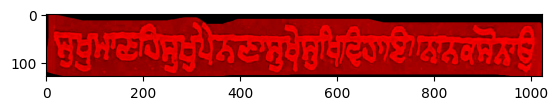

੨੫॥ਸਲੋਕੁਮ:੩ ॥ਜਿਨਿਗੁਰੁਗੋਪਿਆਆਪਣ


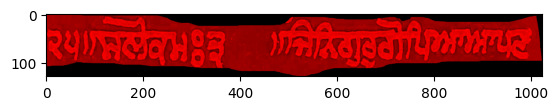

In [ ]:
rnd = np.random.choice(range(len(train_images)),2)

for i in rnd:
    print(train_original_text[i])
    plt.imshow(train_images[i])
    plt.show()

Let's pad the lines to the maximum length

In [ ]:
train_padded_label = pad_sequences(train_labels,
                             maxlen=max_label_len,
                             padding='post',
                             value=len(letters))

val_padded_label = pad_sequences(val_labels,
                             maxlen=max_label_len,
                             padding='post',
                             value=len(letters))

In [ ]:
train_padded_label.shape, val_padded_label.shape

((824, 47), (59, 47))

In [ ]:
train_images = np.asarray(train_images)
train_input_length = np.asarray(train_input_length)
train_label_length = np.asarray(train_label_length)

val_images = np.asarray(val_images)
val_input_length = np.asarray(val_input_length)
val_label_length = np.asarray(val_label_length)

In [ ]:
train_images.shape

(824, 128, 1024, 3)

## Building a model

The model consists of several layers of CNN, GRU and uses ctc_loss. Here is a good video about him in Russian. [Вот](https://www.youtube.com/watch?v=SAfJ6nP2rrI)

In [ ]:
act_model.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 128, 1024, 3)]    0         
_________________________________________________________________
conv2d (Conv2D)              (None, 128, 1024, 64)     1792      
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 63, 512, 64)       0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 63, 512, 128)      73856     
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 30, 256, 128)      0         
_________________________________________________________________
conv2d_2 (Conv2D)            (None, 30, 256, 256)      295168    
_________________________________________________________________
conv2d_3 (Conv2D)            (None, 30, 256, 256)      590080

In [ ]:
#Revised code of Character level Recognition
batch_size = 20
epochs = 15

from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau



# Define a custom metric function for character-level accuracy
def character_accuracy(y_true, y_pred):
    # Convert y_pred to labels
    y_pred_labels = K.ctc_decode(y_pred, input_length=np.ones(y_pred.shape[0]) * y_pred.shape[1], greedy=True)[0][0]
    decoded_output = K.get_value(y_pred_labels)

    # Flatten true labels to compare character by character
    true_labels = K.flatten(y_true)
    decoded_labels = K.flatten(decoded_output)

    # Calculate character-level accuracy
    correct_characters = K.cast(K.equal(true_labels, decoded_labels), dtype='float32')
    accuracy = K.mean(correct_characters)

    return accuracy

# Compile the model with the custom metric
model.compile(loss={'ctc': lambda y_true, y_pred: y_pred}, optimizer='adam', metrics=[character_accuracy])


#model.compile(loss={'ctc': lambda y_true, y_pred: y_pred}, optimizer = 'adam', metrics=['accuracy'])

os.makedirs('checkpoint', exist_ok=True)

filepath="checkpoint/model.hdf5"
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=20)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.7,
                              patience=5, min_lr=0.00001)

checkpoint = ModelCheckpoint(filepath=filepath, monitor='val_accuracy', verbose=1, save_best_only=True, mode='auto')
callbacks_list = [checkpoint,es,reduce_lr]

history = model.fit(x=[train_images, train_padded_label, train_input_length, train_label_length],
                    y=np.zeros(len(train_images)),
                    batch_size=batch_size,
                    epochs=epochs,
                    validation_data=([val_images, val_padded_label, val_input_length, val_label_length], [np.zeros(len(val_images))]),
                    verbose=2,
                    callbacks=callbacks_list)

In [ ]:
batch_size = 20
epochs = 300

from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau

model.compile(loss={'ctc': lambda y_true, y_pred: y_pred}, optimizer = 'adam', metrics=['accuracy'])

os.makedirs('checkpoint', exist_ok=True)

filepath="checkpoint/model.hdf5"
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=20)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.7,
                              patience=5, min_lr=0.00001)

checkpoint = ModelCheckpoint(filepath=filepath, monitor='val_accuracy', verbose=1, save_best_only=True, mode='auto')
callbacks_list = [checkpoint,es,reduce_lr]

history = model.fit(x=[train_images, train_padded_label, train_input_length, train_label_length],
                    y=np.zeros(len(train_images)),
                    batch_size=batch_size,
                    epochs=epochs,
                    validation_data=([val_images, val_padded_label, val_input_length, val_label_length], [np.zeros(len(val_images))]),
                    verbose=2,
                    callbacks=callbacks_list)


Epoch 1/300

Epoch 1: val_accuracy improved from -inf to 0.00000, saving model to checkpoint/model.hdf5


/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


42/42 - 485s - loss: 162.4930 - accuracy: 0.0000e+00 - val_loss: 142.1495 - val_accuracy: 0.0000e+00 - lr: 0.0010 - 485s/epoch - 12s/step
Epoch 2/300

Epoch 2: val_accuracy did not improve from 0.00000
42/42 - 474s - loss: 124.3078 - accuracy: 0.0000e+00 - val_loss: 130.4270 - val_accuracy: 0.0000e+00 - lr: 0.0010 - 474s/epoch - 11s/step
Epoch 3/300

Epoch 3: val_accuracy did not improve from 0.00000
42/42 - 473s - loss: 124.3440 - accuracy: 0.0000e+00 - val_loss: 126.5653 - val_accuracy: 0.0000e+00 - lr: 0.0010 - 473s/epoch - 11s/step
Epoch 4/300

Epoch 4: val_accuracy did not improve from 0.00000
42/42 - 473s - loss: 124.2231 - accuracy: 0.0000e+00 - val_loss: 125.7091 - val_accuracy: 0.0000e+00 - lr: 0.0010 - 473s/epoch - 11s/step
Epoch 5/300

Epoch 5: val_accuracy did not improve from 0.00000
42/42 - 474s - loss: 123.2900 - accuracy: 0.0000e+00 - val_loss: 124.1702 - val_accuracy: 0.0000e+00 - lr: 0.0010 - 474s/epoch - 11s/step
Epoch 6/300

Epoch 6: val_accuracy did not improve fro

In [ ]:
# prompt: Generate code to load the model from drive and perform testing with code

model = keras.models.load_model('/content/drive/MyDrive/model.hdf5')
test_images, test_labels, test_input_length, test_label_length, test_original_text, test_original_image, test_max_label_len = generate_data(lines_val, names_val, image_dir)
test_padded_label = pad_sequences(test_labels,
                             maxlen=max_label_len,
                             padding='post',
                             value=len(letters))
test_images = np.asarray(test_images)
test_input_length = np.asarray(test_input_length)
test_label_length = np.asarray(test_label_length)
pred = model.predict(x=[test_images, test_padded_label, test_input_length, test_label_length])
decoded = K.get_value(K.ctc_decode(pred, input_length=np.ones(pred.shape[0]) * pred.shape[1], greedy=True)[0][0])
decoded_characters = []
for i in range(len(decoded)):
    decoded_characters.append(letters[decoded[i]])
print(decoded_characters)



Let's look at the quality during validation.

In [ ]:
import time

In [ ]:
start = time.time()
act_model.load_weights(filepath)
prediction = act_model.predict(val_images)

decoded = K.ctc_decode(prediction,
                       input_length=np.ones(prediction.shape[0]) * prediction.shape[1],
                       greedy=True)[0][0]
out = K.get_value(decoded)
end = time.time()
print(end-start)


2/2 [==============================] - 13s 5s/step
13.651301383972168


In [ ]:
numCharErr = 0
numCharTotal = 0
numStringOK = 0
numStringTotal = 0

word_eds, word_true_lens = [], []

print('Ground truth -> Recognized')
for i in range(len(out)):
    pred = ''
    for p in out[i]:
        if int(p) != -1:
            pred+=letters[int(p)]
    true = val_original_text[i]

    numStringOK += 1 if true == pred else 0
    numStringTotal += 1
    dist = editdistance.eval(pred, true)
    numCharErr += dist
    numCharTotal += len(true)

    pred_words = pred.split()
    true_words = true.split()
    word_eds.append(editdistance.eval(pred_words, true_words))
    word_true_lens.append(len(true_words))

    print('[OK]' if dist==0 else '[ERR:%d]' % dist,'"1:' + true + '"', '2:->', '"' + pred + '"')

charErrorRate = numCharErr / numCharTotal
wordErrorRate = sum(word_eds) / sum(word_true_lens)
stringAccuracy = numStringOK / numStringTotal
print('Character error rate: %f%%. Word error rate: %f%%. String accuracy: %f%%.' % \
      (charErrorRate*100.0,wordErrorRate*100.0, stringAccuracy*100.0))

Ground truth -> Recognized
[ERR:9] "1:ਤਮਸਮਸਰਜ੍ਵਰਦੂਤੰ॥੫॥ਭ੍ਰਮਿਤਿਨਵਾ" 2:-> "ਹਮਮਮਸਰਜ੍ਰਦੁਤਿ॥ੁ॥ਭ॥ਮਤਿਨਵਾ"
[OK] "1:ਨਾਹੀਥਾਉ॥ਓਹਵੇਲਾਹਥਿਨਆਵਈਫਿਰਿਸਤਿ" 2:-> "ਨਾਹੀਥਾਉ॥ਓਹਵੇਲਾਹਥਿਨਆਵਈਫਿਰਿਸਤਿ"
[ERR:2] "1:ਸਿਖਬੈਠੇਸਤਿਗੁਰਪਾਸਿ॥੨੬॥ਸਲੋਕਮ:੫ ॥" 2:-> "ਸਿਖਬੈਠੇਸਤਿਗੁਰਪਾਸਿ॥॥ਸਲੋਕਮ:੫ ॥"
[OK] "1:ਚੈਸਾਹਿਬਮਾਰਿਆਕਉਣੁਤਿਸਨੋਰਖੈ॥ਨਾਨਕਤਿਸੁਸਰ" 2:-> "ਚੈਸਾਹਿਬਮਾਰਿਆਕਉਣੁਤਿਸਨੋਰਖੈ॥ਨਾਨਕਤਿਸੁਸਰ"
[OK] "1:ਵੇਖੈਤਿਥੈਤਪਾਭਿਟੈਨਾਹੀਧਨਿਬਹੁਤੈਡਿਠੈਤਪੈਧਰਮੁ" 2:-> "ਵੇਖੈਤਿਥੈਤਪਾਭਿਟੈਨਾਹੀਧਨਿਬਹੁਤੈਡਿਠੈਤਪੈਧਰਮੁ"
[ERR:1] "1:ਰੁਘਰੀਬਹਾਲਿਅਨੁਅਪਣੀਪੈਜਰਖਾਈ॥ਨਿੰਦਕਾਪਾਸਹੁ" 2:-> "ਰੁਘਰੀਬਹਾਲਿਅਨੁਅਪਣੀਪੈਜਰਖਾਈ॥ਨਿਦਕਾਪਾਸਹੁ"
[ERR:1] "1:ਆਨੁਅੰਧਾਰੁ॥ਨਾਨਕਮਨਮੁਖਾਨਾਲੋਤੁਟੀਭਲੀਜਿਨਮਾ" 2:-> "ਆਨੁਅੰਧਾਰੁ॥ਨਾਨਕਮਨਮੁਖਾਨਾਲੋਤੁਟੀਭਲੀਜਿਨਮ"
[OK] "1:ਪਿਆਸੇਫਿਰਹਿਭਵੰਦੇ॥ਪੇਡੁਮੁੰਢਾਹੂਕਟਿਆਤਿਸੁ" 2:-> "ਪਿਆਸੇਫਿਰਹਿਭਵੰਦੇ॥ਪੇਡੁਮੁੰਢਾਹੂਕਟਿਆਤਿਸੁ"
[OK] "1:ਰਮਬੀਚਾਰੀ॥ਜਿਓਸੁਮਿਲੈਤਿਸੁਪਾਰਿਉਤਾਰੀ॥ਅੰ" 2:-> "ਰਮਬੀਚਾਰੀ॥ਜਿਓਸੁਮਿਲੈਤਿਸੁਪਾਰਿਉਤਾਰੀ॥ਅੰ"
[OK] "1:ਣਾ॥੪॥ਸਲੋਕਮ:੩ ॥ਕਲਉਮਸਾਜਨੀਕਿਆਸਦਾ" 2:-> "ਣਾ॥੪॥ਸਲੋਕਮ:੩ ॥ਕਲਉਮਸਾਜਨੀਕਿਆਸਦਾ"
[OK] "1:ੜਣਾਕੂੜੁਬੋਲਣਾਮਾਇਆਨਾਲਿਪਿਆਰੁ॥ਨਾਨਕਵਿ" 2:-> "ੜਣਾਕੂੜੁਬੋਲਣਾਮਾਇਆਨਾਲਿਪਿਆਰੁ॥ਨਾਨਕਵਿ"
[ERR:2] "1:॥ਤੂੰਆਪੇਜਲੁਮੀਨਾਹੈਆਪੇਆਪੇਹੀਆਪਿਜਾਲੁ" 2:-> "

We load test images, make predictions and write them to a file.

This laptop is a public baseline. The test sample will be automatically added to the image where the participant uploads the model. Therefore, the following lines are now commented out. And an example of running the model and writing predictions to a file will be carried out on validation images.

In [ ]:
#Для примера работы запуска модели и записи в файл, пусть валидация станет тестовыми изображениями
test_images = val_images
names_test = names_val

In [ ]:
#test_image_dir = 'test/images'
test_image_dir='/content/drive/MyDrive/train/extra'


In [ ]:
test_images = []
names_test = []

for name in  os.listdir(test_image_dir):
     img = cv2.imread(test_image_dir+'/'+name)
     img = process_image(img)
     test_images.append(img)
     names_test.append(name)
test_images = np.asarray(test_images)

In [ ]:
start = time.time()

prediction =act_model.predict(test_images)

decoded = K.ctc_decode(prediction,
                       input_length=np.ones(prediction.shape[0]) * prediction.shape[1],
                       greedy=True)[0][0]

out = K.get_value(decoded)

prediction = []
for i, x in enumerate(out):
    pred = ''
    for p in x:
        if int(p) != -1:
            pred+=letters[int(p)]

    prediction.append(pred)
end = time.time()

print(end - start)

1/1 [==============================] - 1s 621ms/step
0.6891510486602783


In [ ]:
len(prediction)
print(prediction[0])
print(prediction[1])
print(prediction[2])

ਸੈਰਜਾਇ॥ਪਰਮੇਸੁਰਿਜੀਵਾਲਿਆਨਾਨਕਸਿਸੈਧਿ
ਾਅ॥ਨਾਲਾਾਨਨਅਨਾਨਨਅਪਾਸ॥ਸਜ॥
ਨਾਾਆਿਾਸੰਆਾ॥ਸਾਪਾਨਾਸ


In [ ]:
output_dir = '/content/drive/MyDrive/train/t'
os.makedirs(output_dir, exist_ok=True)

for num, (name, line) in enumerate(zip(names_test, prediction)):
    with open(os.path.join(output_dir, name.replace('.jpg', '.txt')), 'w') as file:
        file.write(line)

Let's collect a submission for the platform

In [ ]:
! cp checkpoint/model.hdf5 submit_example/checkpoint/
! zip submit.zip -r submit_example


cp: cannot create regular file 'submit_example/checkpoint/': No such file or directory
	zip warning: name not matched: submit_example

zip error: Nothing to do! (try: zip -r submit.zip . -i submit_example)
